# 

In [6]:
import pandas as pd
import numpy as np
import time

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

df = pd.read_csv("/kaggle/input/datasets/sandiledesmondmfazi/bank-customer-churn/botswana_bank_customer_churn.csv")

print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicates:", df.duplicated().sum())

print("\nTarget distribution:")
print(df["Churn Flag"].value_counts())

print("\nTarget percentage:")
print(
    df["Churn Flag"]
    .value_counts(normalize=True)
    .mul(100)
    .round(4)
)

df = df.drop_duplicates().reset_index(drop=True)

df = df.dropna(subset=["Churn Flag"]).reset_index(drop=True)

df["Churn Flag"] = df["Churn Flag"].astype(int)

df["Date of Birth"] = pd.to_datetime(
    df["Date of Birth"],
    errors="coerce"
)

reference_date = pd.Timestamp("2025-01-01")

df["Age"] = (
    (reference_date - df["Date of Birth"]).dt.days / 365.25
)

df["Age"] = df["Age"].round(1)

df = df.drop(
    columns=[
        "RowNumber",
        "CustomerId",
        "Surname",
        "First Name",
        "Date of Birth",
        "Address",
        "Contact Information",
        "Churn Reason",
        "Churn Date"
    ],
    errors="ignore"
)

if "Balance" in df.columns and "Income" in df.columns:
    df["Balance_Income_Ratio"] = np.where(
        df["Income"] > 0,
        df["Balance"] / df["Income"],
        0
    )

if "Outstanding Loans" in df.columns and "Income" in df.columns:
    df["Loan_Income_Ratio"] = np.where(
        df["Income"] > 0,
        df["Outstanding Loans"] / df["Income"],
        0
    )

if "Balance" in df.columns:
    df["Balance_Log"] = np.log1p(
        df["Balance"].clip(lower=0)
    )

if "Income" in df.columns:
    df["Income_Log"] = np.log1p(
        df["Income"].clip(lower=0)
    )

if "Outstanding Loans" in df.columns:
    df["Outstanding_Loans_Log"] = np.log1p(
        df["Outstanding Loans"].clip(lower=0)
    )

if "NumOfProducts" in df.columns and "Customer Tenure" in df.columns:
    df["Products_Per_Tenure"] = (
        df["NumOfProducts"] /
        (df["Customer Tenure"] + 1)
    )

if "Balance" in df.columns and "NumOfProducts" in df.columns:
    df["Balance_Per_Product"] = np.where(
        df["NumOfProducts"] > 0,
        df["Balance"] / df["NumOfProducts"],
        0
    )

if "NumComplaints" in df.columns and "Customer Tenure" in df.columns:
    df["Complaints_Per_Tenure"] = (
        df["NumComplaints"] /
        (df["Customer Tenure"] + 1)
    )

X = df.drop(columns=["Churn Flag"])
y = df["Churn Flag"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=42
)

print("\nTraining shape:", X_train.shape)
print("Test shape:", X_test.shape)

print("\nTraining distribution:")
print(y_train.value_counts())

print("\nTraining percentage:")
print(
    y_train
    .value_counts(normalize=True)
    .mul(100)
    .round(4)
)

print("\nTest distribution:")
print(y_test.value_counts())

print("\nTest percentage:")
print(
    y_test
    .value_counts(normalize=True)
    .mul(100)
    .round(4)
)

categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numerical_features = [
    col
    for col in X_train.columns
    if col not in categorical_features
]

print("\nCategorical features:")
print(categorical_features)

print("\nNumerical features:")
print(numerical_features)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        )
    ]
)

models = {
    "Decision Tree": DecisionTreeClassifier(
        random_state=42,
        max_depth=10,
        min_samples_leaf=10
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1,
        max_depth=20,
        min_samples_leaf=5
    ),

    "XGBoost": XGBClassifier(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = []

for model_name, model in models.items():

    pipeline = ImbPipeline([
        ("preprocessor", preprocessor),
        (
            "smote",
            SMOTE(
                sampling_strategy=0.5,
                random_state=42
            )
        ),
        ("model", model)
    ])

    start_time = time.time()

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "precision": "precision",
            "recall": "recall",
            "f1": "f1",
            "roc_auc": "roc_auc",
            "pr_auc": "average_precision"
        },
        n_jobs=1,
        return_train_score=False
    )

    elapsed = time.time() - start_time

    results.append({
        "Model": model_name,
        "Strategy": "SMOTE",
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1": scores["test_f1"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean(),
        "PR-AUC": scores["test_pr_auc"].mean(),
        "Time_seconds": elapsed
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by=["PR-AUC", "F1"],
    ascending=False
).reset_index(drop=True)

print("\nSMOTE-ONLY CV RESULTS")
print(results_df.to_string(index=False))

winner = results_df.iloc[0]

print("\nWINNER")
print("Model:", winner["Model"])
print("Strategy:", winner["Strategy"])
print("Accuracy:", winner["Accuracy"])
print("Precision:", winner["Precision"])
print("Recall:", winner["Recall"])
print("F1:", winner["F1"])
print("ROC-AUC:", winner["ROC-AUC"])
print("PR-AUC:", winner["PR-AUC"])

Shape: (115640, 25)

Columns:
['RowNumber', 'CustomerId', 'Surname', 'First Name', 'Date of Birth', 'Gender', 'Marital Status', 'Number of Dependents', 'Occupation', 'Income', 'Education Level', 'Address', 'Contact Information', 'Customer Tenure', 'Customer Segment', 'Preferred Communication Channel', 'Credit Score', 'Credit History Length', 'Outstanding Loans', 'Churn Flag', 'Churn Reason', 'Churn Date', 'Balance', 'NumOfProducts', 'NumComplaints']

Missing values:
RowNumber                               0
CustomerId                              0
Surname                                 0
First Name                              0
Date of Birth                           0
Gender                                  0
Marital Status                          0
Number of Dependents                    0
Occupation                              0
Income                                  0
Education Level                         0
Address                                 0
Contact Information      

In [7]:
import time
import pandas as pd
import numpy as np

from xgboost import XGBClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

final_model = ImbPipeline([
    ("preprocessor", preprocessor),
    ("smote", SMOTE(
        sampling_strategy=0.5,
        random_state=42
    )),
    ("model", xgb_model)
])

train_start = time.time()

final_model.fit(
    X_train,
    y_train
)

train_time = time.time() - train_start

test_start = time.time()

y_pred = final_model.predict(X_test)
y_prob = final_model.predict_proba(X_test)[:, 1]

test_time = time.time() - test_start

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_prob)
pr_auc = average_precision_score(y_test, y_prob)

print("=" * 60)
print("FINAL CHURN TEST RESULTS")
print("=" * 60)

print(f"Accuracy        : {accuracy:.6f}")
print(f"Precision       : {precision:.6f}")
print(f"Recall          : {recall:.6f}")
print(f"F1-Score        : {f1:.6f}")
print(f"ROC-AUC         : {roc_auc:.6f}")
print(f"PR-AUC          : {pr_auc:.6f}")
print(f"Training Time   : {train_time:.2f} seconds")
print(f"Testing Time    : {test_time:.4f} seconds")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Not Churned", "Churned"],
        digits=4
    )
)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

FINAL CHURN TEST RESULTS
Accuracy        : 0.994379
Precision       : 0.969718
Recall          : 0.984626
F1-Score        : 0.977115
ROC-AUC         : 0.999803
PR-AUC          : 0.998634
Training Time   : 42.97 seconds
Testing Time    : 0.5777 seconds

Classification Report:
              precision    recall  f1-score   support

 Not Churned     0.9979    0.9957    0.9968     30464
     Churned     0.9697    0.9846    0.9771      4228

    accuracy                         0.9944     34692
   macro avg     0.9838    0.9902    0.9870     34692
weighted avg     0.9944    0.9944    0.9944     34692


Confusion Matrix:
[[30334   130]
 [   65  4163]]



FINAL TEST PERFORMANCE
                 Metric  XGBoost + SMOTE
               Accuracy          99.4400
              Precision          96.9700
                 Recall          98.4600
               F1-Score          97.7100
                ROC-AUC          99.9800
                 PR-AUC          99.8600
Training Time (seconds)          42.9700
 Testing Time (seconds)           0.5777

CLASSIFICATION REPORT
           Class  Precision  Recall  F1-Score  Support
     Not Churned     0.9979  0.9957    0.9968    30464
         Churned     0.9697  0.9846    0.9771     4228
   Macro Average     0.9838  0.9902    0.9870    34692
Weighted Average     0.9944  0.9944    0.9944    34692

CONFUSION MATRIX
                    Predicted Not Churned  Predicted Churned
Actual Not Churned                  30334                130
Actual Churned                         65               4163


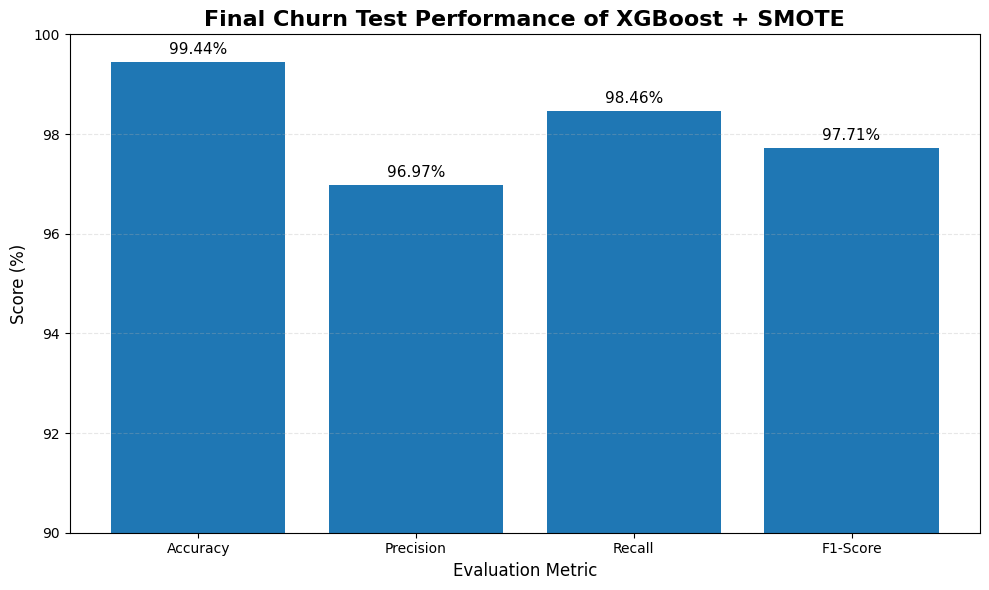

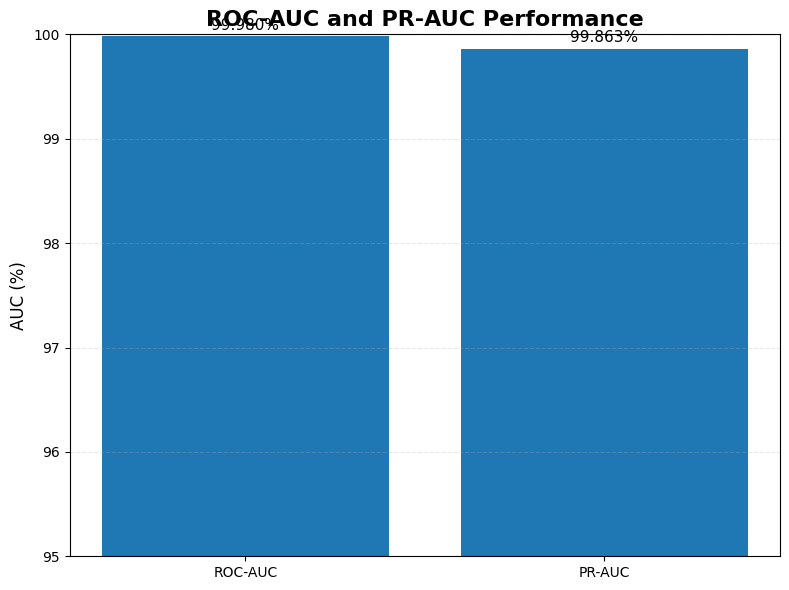

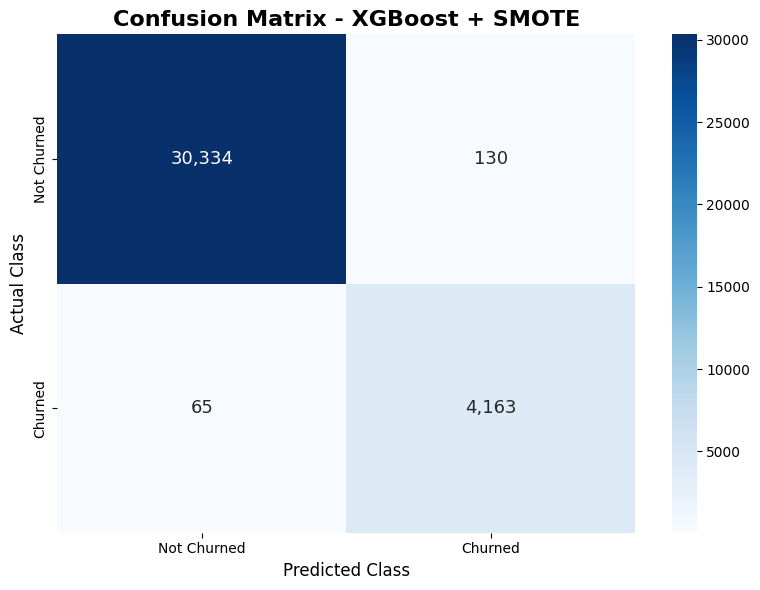

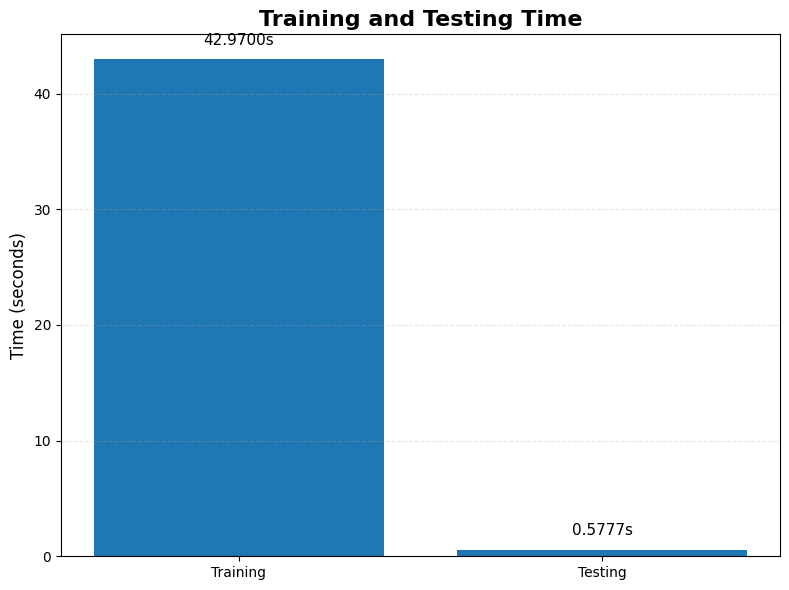


REPORT FILES GENERATED
churn_auc_comparison.png
churn_confusion_matrix.png
churn_performance_metrics.png
churn_training_testing_time.png
classification_report.csv
confusion_matrix.csv
final_test_performance.csv

Output directory: churn_report_outputs


In [8]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

output_dir = "churn_report_outputs"
os.makedirs(output_dir, exist_ok=True)

accuracy = 0.994379
precision = 0.969718
recall = 0.984626
f1 = 0.977115
roc_auc = 0.999803
pr_auc = 0.998634
training_time = 42.97
testing_time = 0.5777

cm = np.array([
    [30334, 130],
    [65, 4163]
])

# ============================================================
# TABLE 1: FINAL TEST PERFORMANCE
# ============================================================

performance_table = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC",
        "PR-AUC",
        "Training Time (seconds)",
        "Testing Time (seconds)"
    ],
    "XGBoost + SMOTE": [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc,
        pr_auc,
        training_time,
        testing_time
    ]
})

performance_table_display = performance_table.copy()

performance_table_display.loc[:5, "XGBoost + SMOTE"] = (
    performance_table_display.loc[:5, "XGBoost + SMOTE"] * 100
).round(2)

performance_table_display.loc[6:, "XGBoost + SMOTE"] = (
    performance_table_display.loc[6:, "XGBoost + SMOTE"].round(4)
)

performance_table_display.to_csv(
    f"{output_dir}/final_test_performance.csv",
    index=False
)

print("\nFINAL TEST PERFORMANCE")
print(performance_table_display.to_string(index=False))


# ============================================================
# TABLE 2: CLASSIFICATION REPORT
# ============================================================

classification_table = pd.DataFrame({
    "Class": [
        "Not Churned",
        "Churned",
        "Macro Average",
        "Weighted Average"
    ],
    "Precision": [
        0.9979,
        0.9697,
        0.9838,
        0.9944
    ],
    "Recall": [
        0.9957,
        0.9846,
        0.9902,
        0.9944
    ],
    "F1-Score": [
        0.9968,
        0.9771,
        0.9870,
        0.9944
    ],
    "Support": [
        30464,
        4228,
        34692,
        34692
    ]
})

classification_table.to_csv(
    f"{output_dir}/classification_report.csv",
    index=False
)

print("\nCLASSIFICATION REPORT")
print(classification_table.to_string(index=False))


# ============================================================
# TABLE 3: CONFUSION MATRIX
# ============================================================

confusion_table = pd.DataFrame(
    cm,
    index=["Actual Not Churned", "Actual Churned"],
    columns=["Predicted Not Churned", "Predicted Churned"]
)

confusion_table.to_csv(
    f"{output_dir}/confusion_matrix.csv"
)

print("\nCONFUSION MATRIX")
print(confusion_table)


# ============================================================
# FIGURE 1: MODEL PERFORMANCE METRICS
# ============================================================

metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]
values = [
    accuracy * 100,
    precision * 100,
    recall * 100,
    f1 * 100
]

plt.figure(figsize=(10, 6))
bars = plt.bar(metrics, values)

plt.title(
    "Final Churn Test Performance of XGBoost + SMOTE",
    fontsize=16,
    fontweight="bold"
)

plt.ylabel("Score (%)", fontsize=12)
plt.xlabel("Evaluation Metric", fontsize=12)
plt.ylim(90, 100)

for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.1,
        f"{value:.2f}%",
        ha="center",
        va="bottom",
        fontsize=11
    )

plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()

plt.savefig(
    f"{output_dir}/churn_performance_metrics.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FIGURE 2: ROC-AUC VS PR-AUC
# ============================================================

auc_names = ["ROC-AUC", "PR-AUC"]
auc_values = [
    roc_auc * 100,
    pr_auc * 100
]

plt.figure(figsize=(8, 6))
bars = plt.bar(auc_names, auc_values)

plt.title(
    "ROC-AUC and PR-AUC Performance",
    fontsize=16,
    fontweight="bold"
)

plt.ylabel("AUC (%)", fontsize=12)
plt.ylim(95, 100)

for bar, value in zip(bars, auc_values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.03,
        f"{value:.3f}%",
        ha="center",
        va="bottom",
        fontsize=11
    )

plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()

plt.savefig(
    f"{output_dir}/churn_auc_comparison.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FIGURE 3: CONFUSION MATRIX
# ============================================================

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt=",d",
    cmap="Blues",
    xticklabels=["Not Churned", "Churned"],
    yticklabels=["Not Churned", "Churned"],
    cbar=True,
    annot_kws={"fontsize": 13}
)

plt.title(
    "Confusion Matrix - XGBoost + SMOTE",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Predicted Class", fontsize=12)
plt.ylabel("Actual Class", fontsize=12)

plt.tight_layout()

plt.savefig(
    f"{output_dir}/churn_confusion_matrix.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FIGURE 4: TRAINING VS TESTING TIME
# ============================================================

time_names = ["Training", "Testing"]
time_values = [
    training_time,
    testing_time
]

plt.figure(figsize=(8, 6))
bars = plt.bar(time_names, time_values)

plt.title(
    "Training and Testing Time",
    fontsize=16,
    fontweight="bold"
)

plt.ylabel("Time (seconds)", fontsize=12)

for bar, value in zip(bars, time_values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 1,
        f"{value:.4f}s",
        ha="center",
        va="bottom",
        fontsize=11
    )

plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()

plt.savefig(
    f"{output_dir}/churn_training_testing_time.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# SUMMARY
# ============================================================

print("\n" + "=" * 60)
print("REPORT FILES GENERATED")
print("=" * 60)

for file in sorted(os.listdir(output_dir)):
    print(file)

print("\nOutput directory:", output_dir)

In [22]:
import os
import shutil
import base64
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import HTML, display

# ============================================================
# CREATE OUTPUT FOLDER
# ============================================================

output_dir = "churn_report_outputs"
os.makedirs(output_dir, exist_ok=True)


# ============================================================
# SAVE CURRENT FIGURE
# ============================================================

plt.savefig(
    f"{output_dir}/figure.png",
    dpi=600,
    bbox_inches="tight"
)


# ============================================================
# SAVE TABLES
# ============================================================

performance_table_display.to_csv(
    f"{output_dir}/final_test_performance.csv",
    index=False
)

classification_table.to_csv(
    f"{output_dir}/classification_report.csv",
    index=False
)

confusion_table.to_csv(
    f"{output_dir}/confusion_matrix.csv"
)


# ============================================================
# CREATE ZIP FILE
# ============================================================

zip_file = shutil.make_archive(
    "churn_report_outputs",
    "zip",
    output_dir
)


# ============================================================
# CREATE DOWNLOAD LINK
# ============================================================

with open(zip_file, "rb") as f:
    data = base64.b64encode(f.read()).decode()

download_link = f'''
<a download="churn_report_outputs.zip"
href="data:application/zip;base64,{data}"
style="
font-size:18px;
font-weight:bold;
color:white;
background:#1976D2;
padding:12px 20px;
border-radius:8px;
text-decoration:none;
">
Download Churn Report Files
</a>
'''

display(HTML(download_link))


# ============================================================
# SHOW SAVED FILES
# ============================================================

print("=" * 60)
print("ALL FILES SAVED SUCCESSFULLY")
print("=" * 60)

for file in sorted(os.listdir(output_dir)):
    print(file)

print("\nZIP file:", zip_file)
print("Click the blue button above to download it to your PC.")

ALL FILES SAVED SUCCESSFULLY
churn_auc_comparison.png
churn_confusion_matrix.png
churn_performance_metrics.png
churn_training_testing_time.png
classification_report.csv
confusion_matrix.csv
figure.png
final_test_performance.csv

ZIP file: /kaggle/working/churn_report_outputs.zip
Click the blue button above to download it to your PC.


<Figure size 640x480 with 0 Axes>